# Transformers


#### A Transformer is a deep learning architecture designed to process sequences of text using self-attention.

- Transformers are the foundation of many modern NLP models, including BERT, GPT, and T5.

- Before Transformers, we used models such as RNNs and LSTMs for NLP tasks.

<img src="https://drive.google.com/thumbnail?id=1unPqGaKftHxp37-F99Bg6hJzFbQdCGC7&sz=w1000" width="700">

In [1]:
%pip -q install transformers torch matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Load a Transformer

We use **DistilBERT**, a  Transformer fine-tuned for positive/negative sentiment classification.

In [2]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

model_name = "distilbert-base-uncased-finetuned-sst-2-english"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForSequenceClassification.from_pretrained(model_name)
model.eval()

# Look inside the Transformer architecture.
print("Transformer layers:", model.config.n_layers)
print("Attention heads per layer:", model.config.n_heads)
print("Hidden size:", model.config.dim)

C:\Users\Majed AL-Hajri\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 17301.59it/s]

Transformer layers: 6
Attention heads per layer: 12
Hidden size: 768



<img src="https://drive.google.com/thumbnail?id=1v2dRK1KR_ydZOknjj8Xv8_wjOdXleDYs&sz=w1000" width="500">

## 2. Tokenizing the text

In [3]:
sentence = "The movie was not good."

# Tokenization: converts text into token IDs
inputs = tokenizer(sentence, return_tensors="pt")

# [CLS] = start token, [SEP] = end token
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

print("Tokens:", tokens)

Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']


## 3. Embeddings and self-attention

Each token ID becomes a **vector (embedding)**. Inside each Transformer layer, **self-attention** lets a token use information from other tokens in the same sentence.

In [4]:
import torch

# Enable attention weights
model.set_attn_implementation("eager")

with torch.no_grad():
    embeddings = model.distilbert.embeddings(inputs["input_ids"])
    outputs = model(**inputs, output_attentions=True)

# Attention from the first layer and first head
attention = outputs.attentions[0][0, 0]

print("Embeddings shape:", embeddings.shape)
print("Attention shape:", attention.shape)
print("Tokens:", tokens)
print("Attention weights:\n", attention)

Embeddings shape: torch.Size([1, 8, 768])
Attention shape: torch.Size([8, 8])
Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']
Attention weights:
 tensor([[0.1145, 0.0938, 0.0681, 0.0701, 0.0596, 0.0800, 0.1593, 0.3546],
        [0.4147, 0.0793, 0.0481, 0.1018, 0.1084, 0.0805, 0.0789, 0.0883],
        [0.1634, 0.0327, 0.0975, 0.0403, 0.1819, 0.1402, 0.0866, 0.2574],
        [0.2882, 0.1014, 0.0504, 0.0669, 0.2180, 0.1009, 0.1231, 0.0511],
        [0.3612, 0.0501, 0.0696, 0.1200, 0.0642, 0.1304, 0.0953, 0.1092],
        [0.3065, 0.0469, 0.1175, 0.1915, 0.0630, 0.0555, 0.1120, 0.1071],
        [0.3505, 0.0935, 0.0572, 0.0753, 0.0972, 0.0964, 0.1165, 0.1135],
        [0.3513, 0.1019, 0.0318, 0.0541, 0.1036, 0.0607, 0.0755, 0.2210]])


## 4. Classification: From Transformer to prediction

The Transformer produces contextual representations. The **classification head** turns them into two scores (*logits*). **Softmax** converts these into probabilities that sum to 1.

In [5]:
# Get prediction scores from the Transformer
with torch.no_grad():
    logits = model(**inputs).logits

# Convert scores into probabilities
probs = torch.softmax(logits, dim=1)[0]

# Display the prediction
prediction = probs.argmax().item()

print("Prediction:", model.config.id2label[prediction])
print("Confidence:", round(probs[prediction].item(), 3))


Prediction: NEGATIVE
Confidence: 1.0



### Task: Exploring Transformer Layers and Attention Heads

Load the pretrained **`bert-base-uncased`** model using Hugging Face Transformers.

1. Write code to print the number of Transformer layers and the number of attention heads per layer.
2. Calculate and print the total number of attention heads across all Transformer layers.
3. Using the sentence `"Transformers use self-attention to understand language."`, extract the attention weights from the **third Transformer layer and second attention head**.
4. Explain what the rows and columns of the attention matrix represent.

## Task Solution

### Load `bert-base-uncased`

In [6]:
from transformers import AutoTokenizer, AutoModel
import torch

bert_name = "bert-base-uncased"
bert_tokenizer = AutoTokenizer.from_pretrained(bert_name)
bert_model = AutoModel.from_pretrained(bert_name, attn_implementation="eager")
bert_model.eval()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   5%|▍         | 9/199 [00:00<00:02, 81.71it/s]

Loading weights:   9%|▉         | 18/199 [00:00<00:02, 80.47it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 859.74it/s]


[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
            (dropout): Dropout(p=0.1, inplace=False)
  

### 1. Number of Transformer layers and attention heads per layer

In [7]:
num_layers = bert_model.config.num_hidden_layers
num_heads = bert_model.config.num_attention_heads

print("Transformer layers:", num_layers)
print("Attention heads per layer:", num_heads)

Transformer layers: 12
Attention heads per layer: 12


### 2. Total number of attention heads across all layers

In [8]:
total_heads = num_layers * num_heads
print(f"Total attention heads: {num_layers} x {num_heads} = {total_heads}")

Total attention heads: 12 x 12 = 144


### 3. Attention weights from the 3rd layer, 2nd head

Python indexing starts at 0, so the third layer is index `2` and the second head is index `1`.

In [9]:
task_sentence = "Transformers use self-attention to understand language."

task_inputs = bert_tokenizer(task_sentence, return_tensors="pt")
task_tokens = bert_tokenizer.convert_ids_to_tokens(task_inputs["input_ids"][0])

with torch.no_grad():
    task_outputs = bert_model(**task_inputs, output_attentions=True)

# attentions: tuple of length num_layers, each of shape (batch, heads, seq_len, seq_len)
layer3_head2 = task_outputs.attentions[2][0, 1]

print("Tokens:", task_tokens)
print("Attention shape:", layer3_head2.shape)
torch.set_printoptions(precision=3, sci_mode=False)
print("Attention weights (layer 3, head 2):")
print(layer3_head2)
print("Each row sums to:", layer3_head2.sum(dim=-1))

Tokens: ['[CLS]', 'transformers', 'use', 'self', '-', 'attention', 'to', 'understand', 'language', '.', '[SEP]']
Attention shape: torch.Size([11, 11])
Attention weights (layer 3, head 2):
tensor([[    0.732,     0.008,     0.011,     0.006,     0.017,     0.007,
             0.010,     0.012,     0.006,     0.039,     0.155],
        [    0.889,     0.005,     0.034,     0.000,     0.003,     0.005,
             0.001,     0.001,     0.000,     0.005,     0.057],
        [    0.143,     0.569,     0.005,     0.035,     0.041,     0.068,
             0.090,     0.000,     0.005,     0.009,     0.034],
        [    0.340,     0.073,     0.002,     0.000,     0.202,     0.081,
             0.064,     0.026,     0.002,     0.028,     0.183],
        [    0.143,     0.070,     0.071,     0.639,     0.012,     0.013,
             0.003,     0.003,     0.014,     0.009,     0.022],
        [    0.113,     0.545,     0.012,     0.020,     0.111,     0.010,
             0.072,     0.000,     0.

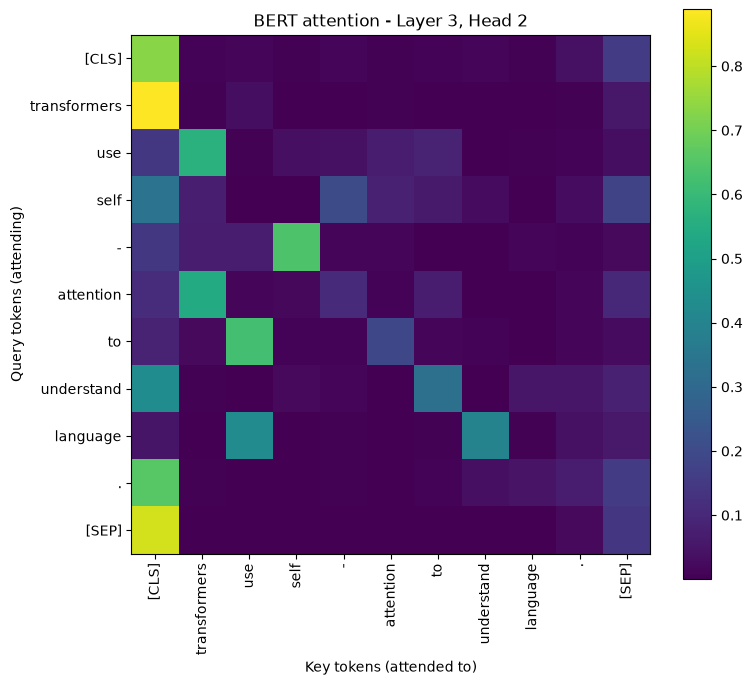

In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(layer3_head2.numpy(), cmap="viridis")
ax.set_xticks(range(len(task_tokens)))
ax.set_yticks(range(len(task_tokens)))
ax.set_xticklabels(task_tokens, rotation=90)
ax.set_yticklabels(task_tokens)
ax.set_xlabel("Key tokens (attended to)")
ax.set_ylabel("Query tokens (attending)")
ax.set_title("BERT attention - Layer 3, Head 2")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

### 4. What do the rows and columns of the attention matrix represent?

The attention matrix has shape `(seq_len, seq_len)`, where `seq_len` is the number of tokens (including `[CLS]` and `[SEP]`).

- **Rows = query tokens.** Row *i* belongs to the token that is "looking" at the sentence. It shows how token *i* distributes its attention over all tokens when building its new contextual representation.
- **Columns = key tokens.** Column *j* belongs to the token being "looked at". Entry `[i, j]` is how much token *i* attends to token *j*, i.e. how much of token *j*'s value vector is mixed into token *i*'s output.
- Because each row is produced by a **softmax**, every row sums to 1, so a row is a probability distribution over the sentence.
- A large value at `[i, j]` means that, for this layer and head, token *j* is important for understanding token *i*. Different heads learn different patterns (e.g. attending to the next/previous token, to `[SEP]`/`[CLS]`, or to related words).